This model demonstrates how the union operator can be used to create a cell with non-contiguous regions.

In [1]:
import openmc 

# Surface definitions
s1 = openmc.Sphere(x0=-1,r=2, surface_id=1)
s2 = openmc.Sphere(x0=1,r=2,surface_id =2)
s3 = openmc.Sphere(r=5,surface_id = 3)

In [2]:
# Cell definitions
c1 = openmc.Cell(cell_id=1,fill=None,region=(+s2 & -s1))
c2 = openmc.Cell(cell_id=2,fill=None,region=(-s2 & +s1))
c3 = openmc.Cell(cell_id=3,fill=None,region=((-s3 &  +s1 & +s2) | (-s1 & -s2)))
c4 = openmc.Cell(cell_id=4,fill=None,region=(+s3))

geometry=openmc.Geometry([c1,c2,c3,c4])
geometry.export_to_xml()

material=openmc.Materials()
material.cross_sections='/home/jovibuca/endf/endfb-viii.0-hdf5/cross_sections.xml'
material.export_to_xml()

setting = openmc.Settings()
setting.export_to_xml()

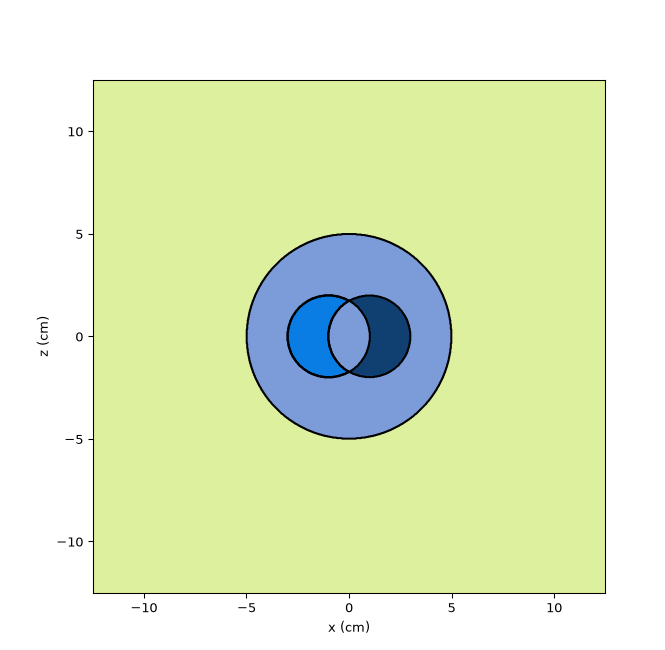